# 实验课 05：把单层学习扩展到各层

第四课只给第 14 层训练了索引器。这一课让完整 Qwen3-0.6B 为每个目标层分别提供 Q/K/V，再用这批固定数组训练该层自己的索引器。**训练完前一层，不把它接回模型改变下一层的输入**；各层教师都来自原完整读取路径。

项目称这一步为 **G3b-lite：各层索引器训练**。27 层新训练，第 14 层直接复用相同条件下已训练的参数，合计提供全部 28 层索引器。主体权重冻结。

每份 T1 资料要求按编号取一个四位值。读取规则继续保留开头 4 个和最近 64 个位置，再按请求第一步长度的 1/8 固定额外名额。C 在剩余位置均匀随机选；D0 用初始参数；D 用训练后参数；R 用完整教师权重选。索引从主 RoPE 前 Q/K 投影到 32 维，索引空间不额外旋转，配置记作“索引位置设置 P0，r=32”。

Notebook 默认读取归档、重算图表。

In [1]:
from pathlib import Path
import importlib.util, ast, json
from IPython.display import display, Markdown, Code
ROOT=Path.cwd()
if not (ROOT/'scripts/g3b_report.py').exists(): ROOT=ROOT.parent
spec=importlib.util.spec_from_file_location('g3b_report',ROOT/'scripts/g3b_report.py')
report=importlib.util.module_from_spec(spec);spec.loader.exec_module(report)
evidence=report.read_evidence();summary=report.summarize(evidence)
print('正式run:',summary['run_id'])
print('运行源码:',summary['run_commit'])
print('完整层数:',len(summary['layers']))
import sys
sys.path.insert(0, str(ROOT / "scripts"))
from teaching_display import details, show_figure


正式run: g3b-20261018T142640Z-formal
运行源码: 2b6db0bc95641403ce5d728bcdbc4a16c209cf4a
完整层数: 28


## 1. 先区分三种资料身份

训练：G3a原有48份，允许更新参数。开发诊断：旧16份，不更新参数，但已经被分析，不能叫新的独立验证。最终测试：另一个种子产生的32份新T1，在G3b阶段不做模型评分。

第14层在相同48份、相同初始化与50轮下已经完成训练；本轮校验原参数和输入哈希后直接复用。其他27层使用同一基础种子派生的固定初始化，不搜索种子、层、ρ或轮数。

<details>
<summary>记录中的状态与来源标签</summary>

`FROZEN_NOT_EVALUATED` 是新测试资料登记时的状态，表示当时尚未评分；其已完成结果在第七课。来源标签 `reused_G3a` 是直接复用第 14 层，`new_training` 是本轮新训练。

</details>

In [2]:
plan=json.loads(evidence['files']['source/configs/g3bg4lite_test_plan.json'])
print('最终测试登记状态:',plan['status_at_registration'])
print('最终测试数量/数据哈希:',plan['count'],plan['data_sha256'])
print('与已存资料/编号值绑定重合:',plan['old_prefix_overlap'],plan['old_record_bindings_overlap'])
print('复用层:',[x['layer_index']+1 for x in summary['layers'] if x['origin']=='reused_G3a'])

最终测试登记状态: FROZEN_NOT_EVALUATED
最终测试数量/数据哈希: 32 1e17405456f75bedecee2863eb31faf7c34b957ce5da7134887dbfbefc825633
与已存资料/编号值绑定重合: 0 0
复用层: [14]


## 2. 逐层训练，保持主模型不动

对当前目标层，主模型在 MPS/bf16 上完整处理每份资料和问题，只保存这一层后缀倒数第 24/16/8/1 个位置的 Q，以及对应历史 K/V。本批固定模板中，四个位置分别是问句里的“数值”“四位”、用户消息结束标记后的换行、空 thinking 模板后的两个换行；后缀共有 35 个 token，其中问句占 26 个。64 份该层特征 detach 后存放在 CPU 内存；教师在 CPU/fp32 计算。

<!-- lesson05-mechanism-svg: source reports/figures/05_independent_layer_training.svg -->
<figure id="independent-layer-training" style="width:50%;max-width:50%;min-width:0;margin:24px auto;">
  <div role="region" aria-label="图 5-1。训练下一层时，仍由完整模型提供特征" tabindex="0" style="width:100%;max-width:100%;box-sizing:border-box;border:1px solid #dce3ec;border-radius:12px;background:#fff;">
    <img alt="图 5-1。同一批48份训练和16份旧开发资料由冻结完整模型处理。针对当前目标层提取Q/K/V，训练本层Wq/Wk50轮，冻结后局部评测，保存本层参数指标并释放临时特征，再改为提取下一层。27层新训练，第14层复用。每一层的特征来自完整路径，不由前一层稀疏输出提供；32份新最终测试资料不参与此过程。" width="1440" height="1020" src="" style="display:block;width:100%;max-width:100%;min-width:0;height:auto;" />
  </div>
  <figcaption style="margin-top:10px;color:#475569;font-size:0.95em;line-height:1.6;text-align:center;"><strong>图 5-1。</strong>左侧完整模型提供每层的训练特征；右侧仅更新当前层索引。下一层仍从左侧提取特征。 <a href="../reports/figures/05_independent_layer_training.svg">打开 SVG 原图</a>。</figcaption>
</figure>
<!-- /lesson05-mechanism-svg -->

随后更新这一层新增的 Wq/Wk。以第 1 层为例，一轮依次读取 48 份训练资料：每份取四个查询位置，每个查询有 8 个 KV 组；用当前 Wq/Wk 给候选历史位置打分，将候选 softmax 与完整注意力提供的候选分布比较，汇总有效查询/组的 KL，再做一次参数更新。固定做 50 轮，旧 16 份开发资料不进入这些更新。

评测时拿同一份保存的 Q/K/V 分别运行 C、初始索引 D0、最终索引 D 和教师选位 R。各方法选好位置后，合并首部/近期必留位置，用原主注意力权重在入选集合内重新归一化并加权 V，再与完整读出比较。**这份局部读出在比较后结束，不会送入第 2 层。**

第 1 层参数和指标保存后，释放临时特征；处理第 2 层时，再让未改的完整模型提供第 2 层特征。依此处理其余层，第 14 层直接复用原参数。训练在 MPS/fp32，最终局部评测在 CPU/fp32。

<details>
<summary>完整特征的归档范围</summary>

每层只保留预先指定的资料序号 0 和 48 的完整特征，其余完整数组记指纹后释放。精简归档保留输入、参数、指标等证据，但不能直接重做全部特征级审计。

</details>

In [3]:
source=evidence['files']['source/src/attention_lab/g3b.py'].decode()
node=next(x for x in ast.parse(source).body if getattr(x,'name',None)=='train_layer')
whole=ast.get_source_segment(source,node)
body=whole[whole.index('            optimizer.zero_grad'):whole.index('            if any(not torch.isfinite(p).all()')]
print('一份训练资料对应的实际更新段（来自该次运行源码）：')
display(Code(body,language='python'))
with details('展开每层配置、初始化、完整训练循环与参数保存'):
    for name in ['layer_config','train_layer']:
        node=next(x for x in ast.parse(source).body if getattr(x,'name',None)==name)
        display(Code(ast.get_source_segment(source,node),language='python'))
print('主体参数在特征提取前后相同：',evidence['manifest']['body_hash_before']==evidence['manifest']['body_hash_after'])

一份训练资料对应的实际更新段（来自该次运行源码）：


optimizer.zero_grad(set_to_none=True)
            loss = loss_for_document(trained, rows[i])
            if loss is None:
                continue
            if not torch.isfinite(loss):
                raise RuntimeError("nonfinite loss")
            loss.backward()
            if any(p.grad is None or not torch.isfinite(p.grad).all() for p in trained.parameters()):
                raise RuntimeError("disconnected/nonfinite index gradient")
            norm = torch.nn.utils.clip_grad_norm_(trained.parameters(), cfg["gradient_clip_norm"])
            if not torch.isfinite(norm):
                raise RuntimeError("nonfinite gradient norm")
            optimizer.step()

主体参数在特征提取前后相同： True


## 3. 不把第 14 层的成功乘以 28

全部层都报告，灰带是复用的第 14 层。**KL**比较教师和索引在候选域的条件分布；**coverage**是入选候选保留的教师权重占候选总权重的比例；**m_C**是候选域在完整教师中原有的总权重。这里不数目标记录的位置。

**相对 L2**是在同一份完整路径特征上，比较子集与完整注意力的 `o_proj` 前读出。一次比较对应一个查询位置、一个 KV 组：将本组两个头的 128 维输出合成 256 维，计算少读与完整读出的差，分母为完整 256 维读出的范数。每项先在资料内平均查询/组，再平均资料。它们都是旧开发集的局部指标，不是整模型回答分数。

当某个查询/组的候选总权重 `m_C<1e-4` 时，这一行不参与 KL 训练，也不纳入 KL、条件 coverage 的均值。**候选总权重、遗漏完整权重和局部输出 RMSE/相对 L2 仍然计算并保留。** “跳过”不表示整行数据无效，也不把未纳入的指标填成零。均匀教师下，同名额的 coverage 本就可能相近。

本批 28 层在旧开发资料上的平均 KL、条件覆盖率、局部输出相对 L2 都相对 D0 改善。“28/28”是旧开发资料上各层均值的比较。


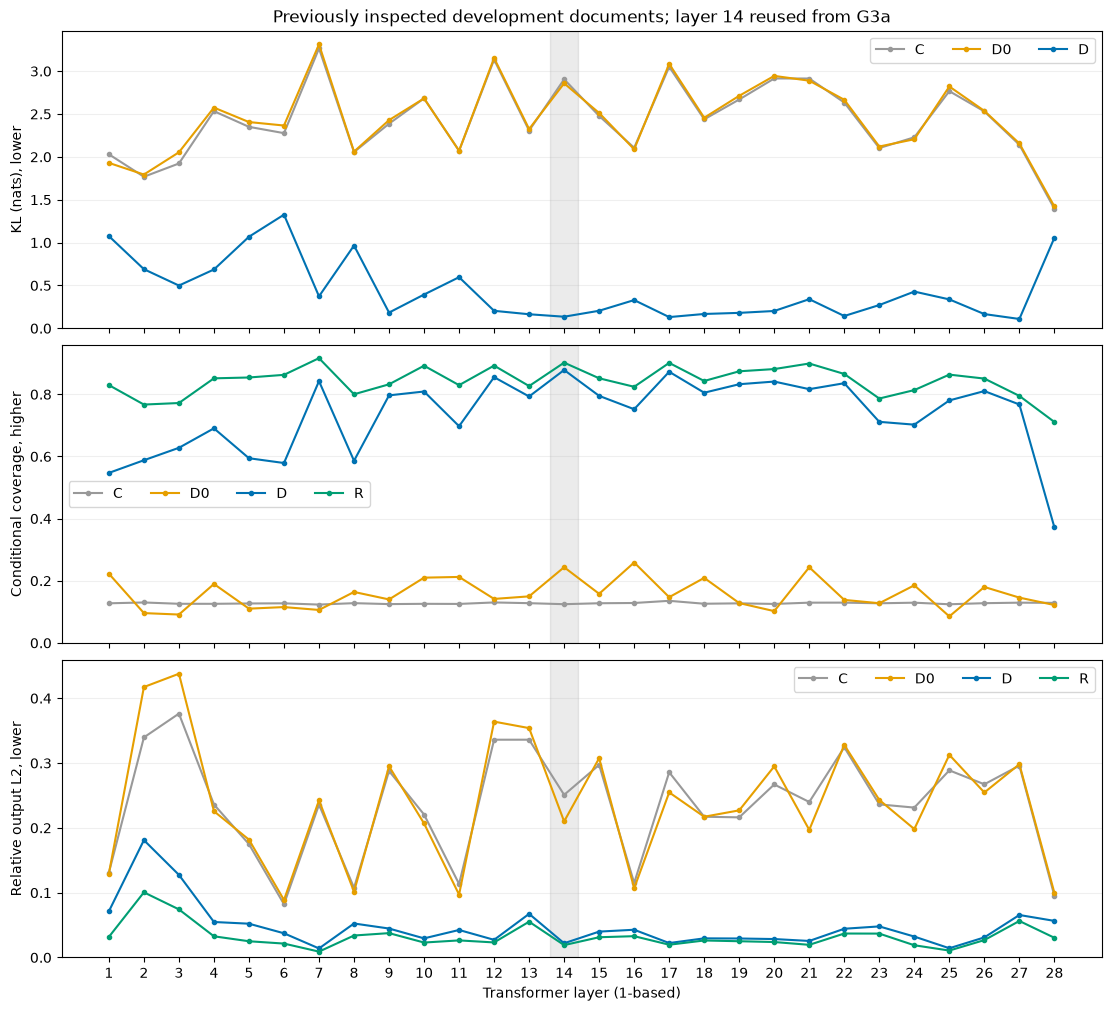

开发资料上平均指标改善的层数： {'kl': 28, 'coverage': 28, 'output_relative_l2': 28}


层,来源,开发 KL：D0→D,开发 coverage：D0→D,开发相对输出误差：D0→D,m_C
1,本阶段新训练,1.9298 → 1.0756,0.2227 → 0.5471,0.1295 → 0.0713,0.3045
2,本阶段新训练,1.7939 → 0.6898,0.0959 → 0.5879,0.4173 → 0.1811,0.3958
3,本阶段新训练,2.0534 → 0.4988,0.0913 → 0.6279,0.4378 → 0.1275,0.3648
4,本阶段新训练,2.5747 → 0.6862,0.1896 → 0.6905,0.2257 → 0.0548,0.1269
5,本阶段新训练,2.4061 → 1.0681,0.1102 → 0.5943,0.1819 → 0.0522,0.1051
6,本阶段新训练,2.3656 → 1.3256,0.1153 → 0.5789,0.0888 → 0.0374,0.0465
7,本阶段新训练,3.3120 → 0.3730,0.1061 → 0.8425,0.2425 → 0.0140,0.1811
8,本阶段新训练,2.0612 → 0.9658,0.1639 → 0.5862,0.1015 → 0.0525,0.0722
9,本阶段新训练,2.4286 → 0.1835,0.1399 → 0.7967,0.2950 → 0.0447,0.1626
10,本阶段新训练,2.6820 → 0.3940,0.2100 → 0.8090,0.2068 → 0.0295,0.1850


In [4]:
import matplotlib.pyplot as plt
fig=report.plot_layers(summary)
show_figure(fig, "5-2", "28 层索引器在旧开发资料上的局部指标")
print('开发资料上平均指标改善的层数：',summary['development_improved_layers'])
with details('展开全部 28 层数值；表中每行均保留'):
    display(Markdown(report.table(summary)))


## 4. 哪些差异值得带到真实推理中检查？

所有 28 层均进入后续部署，未按局部误差排序筛选层；排序只用于补充诊断。

<details>
<summary>展开局部误差排序的解释限制</summary>

不同层的 Q/K/V 分布不同，局部误差也不同。下面按开发资料上的误差排序；这只能提示风险，不能定位最终答错的原因。所有 28 层均进入后续部署，未按这份排序筛选层。

</details>


In [5]:
ranked=sorted(summary['layers'],key=lambda x: x['aggregate']['development']['D']['output_relative_l2'] or -1,reverse=True)
lines=['| 局部误差较大的层 | 候选原权重 | 条件覆盖 | 相对输出误差 |','|---:|---:|---:|---:|']
for row in ranked[:5]:
    d=row['aggregate']['development']['D']
    lines.append(f"| {row['layer_index']+1} | {d['candidate_mass']:.4f} | {d['coverage']:.4f} | {d['output_relative_l2']:.4f} |")
display(Markdown('\n'.join(lines)))

| 局部误差较大的层 | 候选原权重 | 条件覆盖 | 相对输出误差 |
|---:|---:|---:|---:|
| 2 | 0.3958 | 0.5879 | 0.1811 |
| 3 | 0.3648 | 0.6279 | 0.1275 |
| 1 | 0.3045 | 0.5471 | 0.0713 |
| 13 | 0.2622 | 0.7931 | 0.0673 |
| 27 | 0.1500 | 0.7673 | 0.0656 |

## 5. 下一阶段改变了什么？

这里训练和评测都给各方法完整路径的同一份 Q/K/V。部署后，前层少读会改变后层输入，后层索引器面对的状态可能不同。

因此第六课 **G3c** 先固定同一串 token，比较各路径自己的状态；第七课 **G4-lite** 再用新资料让各方法自由生成。后续直接使用冻结参数，未收集稀疏路径状态追加训练。

In [6]:
budget=evidence['budget']
print('到G3b结束共享新增设备秒数:',budget['used_seconds'],'/',budget['limit_seconds'])
print('此前G3a账保留:',budget['prior_ledger'],budget['prior_g3a_seconds'])
print('参数身份清单：reports/g3b_parameters.json')
print('复现报告：python scripts/g3b_report.py；不启动模型。')

到G3b结束共享新增设备秒数: 3537.073182791937 / 14400
此前G3a账保留: runs/g3a-budget-20261018.json 313.80082804203266
参数身份清单：reports/g3b_parameters.json
复现报告：python scripts/g3b_report.py；不启动模型。
